In [2]:
!pip install imagecodecs tifffile

In [3]:
import tifffile
import numpy as np
from PIL import Image, ImageDraw
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import os

def get_slide_info_tifffile(svs_path: Path, level_str: str):
    """Alternative slide info function using tifffile"""
    try:
        levels = read_svs_with_tifffile(svs_path)
        if not levels:
            return None, 1.0, 0
            
        level_count = len(levels)
        
        # Determine level index
        if level_str == 'high':
            level_idx = 0
        elif level_str == 'medium':
            level_idx = level_count // 3 if level_count > 1 else 0
        elif level_str == 'low':
            level_idx = level_count - 1
        else:
            level_idx = int(level_str)
        
        # Simple downsample approximation
        if level_count > 0:
            base_dims = levels[0].shape[:2][::-1]  # (width, height)
            if level_idx < len(levels):
                current_dims = levels[level_idx].shape[:2][::-1]
                downsample = base_dims[0] / current_dims[0] if current_dims[0] > 0 else 1.0
            else:
                downsample = 1.0
                level_idx = 0
        else:
            downsample = 1.0
        
        return levels, downsample, level_idx
    except Exception as e:
        print(f"Error with tifffile: {e}")
        return None, 1.0, 0

def read_svs_with_tifffile(svs_path):
    """Read SVS file using tifffile with better error handling"""
    try:
        with tifffile.TiffFile(svs_path) as tif:
            # Get all pages (levels)
            levels = []
            for i, page in enumerate(tif.pages):
                try:
                    level_img = page.asarray()
                    levels.append(level_img)
                    print(f"Level {i}: {level_img.shape}")
                except Exception as page_error:
                    print(f"Could not read level {i}: {page_error}")
                    continue
            return levels if levels else None
    except Exception as e:
        print(f"Error reading SVS with tifffile: {e}")
        return None


In [6]:
import tifffile
import numpy as np
from PIL import Image, ImageDraw
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import os

def get_slide_info_tifffile(svs_path: Path, level_str: str):
    """Alternative slide info function using tifffile"""
    try:
        levels = read_svs_with_tifffile(svs_path)
        if not levels:
            return None, 1.0, 0
            
        level_count = len(levels)
        
        # Determine level index
        if level_str == 'high':
            level_idx = 0
        elif level_str == 'medium':
            level_idx = level_count // 3 if level_count > 1 else 0
        elif level_str == 'low':
            level_idx = level_count - 1
        else:
            level_idx = int(level_str)
        
        # Simple downsample approximation
        if level_count > 0:
            base_dims = levels[0].shape[:2][::-1]  # (width, height)
            if level_idx < len(levels):
                current_dims = levels[level_idx].shape[:2][::-1]
                downsample = base_dims[0] / current_dims[0] if current_dims[0] > 0 else 1.0
            else:
                downsample = 1.0
                level_idx = 0
        else:
            downsample = 1.0
        
        return levels, downsample, level_idx
    except Exception as e:
        print(f"Error with tifffile: {e}")
        return None, 1.0, 0

def read_svs_with_tifffile(svs_path):
    """Read SVS file using tifffile with better error handling"""
    try:
        with tifffile.TiffFile(svs_path) as tif:
            # Get all pages (levels)
            levels = []
            for i, page in enumerate(tif.pages):
                try:
                    level_img = page.asarray()
                    levels.append(level_img)
                    print(f"Level {i}: {level_img.shape}")
                except Exception as page_error:
                    print(f"Could not read level {i}: {page_error}")
                    continue
            return levels if levels else None
    except Exception as e:
        print(f"Error reading SVS with tifffile: {e}")
        return None

def generate_training_data_smart_sampling(
    annotation_dir: str,
    svs_path_str: str,
    image_output_dir: str,
    mask_output_dir: str,
    overlay_output_dir: str,
    patch_size: int = 256,
    level_str: str = 'medium',
    max_patches: int = 1000,
    samples_per_csv: int = 50
):
    """
    Smart sampling: Take equal samples from each CSV file to ensure diversity
    """
    # Setup paths
    annotation_dir = Path(annotation_dir)
    svs_path = Path(svs_path_str)
    image_output_dir = Path(image_output_dir)
    mask_output_dir = Path(mask_output_dir)
    overlay_output_dir = Path(overlay_output_dir)
    
    if not svs_path.exists():
        print(f"Error: SVS slide not found at '{svs_path}'")
        return
        
    image_output_dir.mkdir(parents=True, exist_ok=True)
    mask_output_dir.mkdir(parents=True, exist_ok=True)
    overlay_output_dir.mkdir(parents=True, exist_ok=True)

    # Load slide
    print("Loading slide...")
    result = get_slide_info_tifffile(svs_path, level_str)
    if result[0] is None:
        print("Failed to load slide")
        return
    
    slide_data, downsample, level_idx = result
    print(f"Loaded slide with {len(slide_data)} levels, using level {level_idx}")

    # Smart sampling: Take equal samples from each CSV
    print("Smart sampling from ALL CSV files...")
    try:
        csv_files = list(annotation_dir.glob("*-features.csv"))
        if not csv_files:
            print(f"No CSV files found in {annotation_dir}")
            return
        
        print(f"Found {len(csv_files)} CSV files")
        
        sampled_dfs = []
        for csv_file in tqdm(csv_files, desc="Sampling from each CSV"):
            try:
                df = pd.read_csv(csv_file, on_bad_lines='skip')
                if 'Polygon' in df.columns and len(df) > 0:
                    # Take sample from this CSV
                    sample_size = min(samples_per_csv, len(df))
                    sampled_df = df.sample(n=sample_size, random_state=42)
                    sampled_dfs.append(sampled_df)
            except Exception as e:
                print(f"Error reading {csv_file}: {e}")
                continue
        
        if not sampled_dfs:
            print("No valid data found in any CSV files")
            return
            
        all_annotations_df = pd.concat(sampled_dfs, ignore_index=True)
        print(f"Combined sample size: {len(all_annotations_df)}")
        
        # Remove duplicates and take final sample
        all_annotations_df.drop_duplicates(subset=['Polygon'], inplace=True)
        if len(all_annotations_df) > max_patches:
            all_annotations_df = all_annotations_df.sample(n=max_patches, random_state=42)
        
        print(f"Final dataset size: {len(all_annotations_df)} patches")
        
    except Exception as e:
        print(f"Error loading CSVs: {e}")
        return

    # Quick spatial indexing
    print("Building quick spatial index...")
    annotation_list = []
    for idx, row in tqdm(all_annotations_df.iterrows(), total=len(all_annotations_df)):
        try:
            poly_str = str(row['Polygon']).strip()
            if not poly_str or poly_str == 'nan':
                continue
                
            cleaned_str = poly_str.strip('[]')
            coords_list = cleaned_str.split(':')
            
            if len(coords_list) % 2 != 0:
                continue
                
            poly_coords_abs = np.array(coords_list, dtype=np.float32).reshape(-1, 2)
            center_x, center_y = poly_coords_abs.mean(axis=0)
            
            annotation_list.append({
                'idx': idx,
                'coords': poly_coords_abs,
                'center_x': center_x,
                'center_y': center_y,
                'original_row': row
            })
        except Exception as e:
            continue

    print(f"Successfully processed {len(annotation_list)} annotations for patch extraction")

    # Process annotations
    print(f"Extracting patches from slide...")
    
    full_slide_img = slide_data[level_idx]
    if len(full_slide_img.shape) == 3:
        slide_height, slide_width = full_slide_img.shape[:2]
    else:
        slide_height, slide_width = full_slide_img.shape
        full_slide_img = np.stack([full_slide_img] * 3, axis=-1)
    
    print(f"Slide dimensions: {slide_width} x {slide_height}")
    
    processed_count = 0
    skipped_count = 0
    
    for i, ann in tqdm(enumerate(annotation_list), total=len(annotation_list)):
        if processed_count >= max_patches:
            break
            
        center_x_scaled = int(ann['center_x'] / downsample)
        center_y_scaled = int(ann['center_y'] / downsample)
        
        half_patch = patch_size // 2
        patch_tl_x = center_x_scaled - half_patch
        patch_tl_y = center_y_scaled - half_patch
        
        # Check boundaries
        if (patch_tl_x < 0 or patch_tl_y < 0 or 
            patch_tl_x + patch_size > slide_width or 
            patch_tl_y + patch_size > slide_height):
            skipped_count += 1
            continue

        try:
            # Extract patch
            patch_array = full_slide_img[patch_tl_y:patch_tl_y+patch_size, 
                                        patch_tl_x:patch_tl_x+patch_size]
            
            # Skip if patch is too small (boundary issues)
            if patch_array.shape[0] != patch_size or patch_array.shape[1] != patch_size:
                skipped_count += 1
                continue
            
            if len(patch_array.shape) == 2:
                patch_array = np.stack([patch_array] * 3, axis=-1)
            elif patch_array.shape[2] == 4:
                patch_array = patch_array[:, :, :3]
                
            base_image = Image.fromarray(patch_array.astype(np.uint8))
            
            # Create mask (just the current annotation)
            mask_image = Image.new('L', (patch_size, patch_size), 0)
            draw_mask = ImageDraw.Draw(mask_image)
            
            transformed_poly = [
                ((vx - patch_tl_x * downsample) / downsample, 
                 (vy - patch_tl_y * downsample) / downsample)
                for vx, vy in ann['coords']
            ]
            draw_mask.polygon(transformed_poly, fill=255)
            
            # Create overlay
            overlay_image = Image.new("RGBA", (patch_size, patch_size), (255, 255, 255, 0))
            draw_overlay = ImageDraw.Draw(overlay_image)
            draw_overlay.polygon(transformed_poly, fill=(0, 255, 0, 100), outline=(0, 255, 0, 200))
            
            # Save all three types
            output_filename = f"patch_{processed_count:06d}.png"
            base_image.save(image_output_dir / output_filename)
            mask_image.save(mask_output_dir / output_filename)
            
            # Combine for overlay
            base_rgba = base_image.convert('RGBA')
            combined_overlay = Image.alpha_composite(base_rgba, overlay_image).convert("RGB")
            combined_overlay.save(overlay_output_dir / output_filename)
            
            processed_count += 1
            
            if processed_count % 100 == 0:
                print(f"Processed {processed_count} patches...")
            
        except Exception as e:
            skipped_count += 1
            continue

    print(f"\nSuccessfully generated {processed_count} training patches!")
    print(f"Stats:")
    print(f"   - Processed: {processed_count} patches")
    print(f"   - Skipped (boundaries): {skipped_count}")
    print(f"   - Total annotations considered: {len(annotation_list)}")
    print(f"   - Output directories:")
    print(f"        Images: {image_output_dir}")
    print(f"        Masks: {mask_output_dir}")
    print(f"        Overlays: {overlay_output_dir}")

# Configuration

# Run the smart sampling function
generate_training_data_smart_sampling(
    annotation_dir=ANNOTATION_DIR,
    svs_path_str=SVS_FILE_PATH,
    image_output_dir=IMAGE_OUTPUT_DIR,
    mask_output_dir=MASK_OUTPUT_DIR,
    overlay_output_dir=OVERLAY_OUTPUT_DIR,
    patch_size=256,
    level_str='medium',
    max_patches=2000,
    samples_per_csv=30
)

Loading slide...
Level 0: (77786, 99599, 3)
Level 1: (768, 983, 3)
Level 2: (19446, 24899, 3)
Level 3: (4861, 6224, 3)
Level 4: (2430, 3112, 3)
Loaded slide with 5 levels, using level 1
Smart sampling from ALL CSV files...
Found 475 CSV files


Sampling from each CSV: 100%|██████████| 475/475 [00:08<00:00, 53.41it/s]


Combined sample size: 8670
Final dataset size: 2000 patches
Building quick spatial index...


100%|██████████| 2000/2000 [00:00<00:00, 9201.68it/s]


Successfully processed 2000 annotations for patch extraction
Extracting patches from slide...
Slide dimensions: 983 x 768


  8%|▊         | 159/2000 [00:02<00:29, 62.97it/s]

... (21 outputs left out)

 94%|█████████▍| 1882/2000 [00:27<00:01, 65.76it/s]

Processed 1200 patches...


100%|██████████| 2000/2000 [00:29<00:00, 67.06it/s]


Successfully generated 1290 training patches!
Stats:
   - Processed: 1290 patches
   - Skipped (boundaries): 710
   - Total annotations considered: 2000
   - Output directories:
        Images: /kaggle/working/training_data/images
        Masks: /kaggle/working/training_data/masks
        Overlays: /kaggle/working/training_data/overlays


In [2]:
ANNOTATION_DIR = '/kaggle/input/lungs-data/annotations/TCGA-NJ-A4YP-01Z-00-DX1.148BFF66-4DC7-468C-8783-97F27C2E1245.svs'
SVS_FILE_PATH = '/kaggle/input/lungs-data/dataset/LUAD/TCGA-NJ-A4YP-01Z-00-DX1.148BFF66-4DC7-468C-8783-97F27C2E1245.svs'

IMAGE_OUTPUT_DIR = '/kaggle/working/training_data/images'
MASK_OUTPUT_DIR = '/kaggle/working/training_data/masks'
OVERLAY_OUTPUT_DIR = '/kaggle/working/training_data/overlays'

PATCH_SIZE = 256
LEVEL = 'medium'

In [8]:
import os
import shutil
from pathlib import Path
import random

def split_training_data(
    images_dir: str,
    masks_dir: str, 
    overlays_dir: str,
    output_base_dir: str,
    train_ratio: float = 0.7,
    val_ratio: float = 0.15,
    test_ratio: float = 0.15,
    seed: int = 42
):
    """
    Split the generated patches into train/val/test sets
    """
    images_dir = Path(images_dir)
    masks_dir = Path(masks_dir)
    overlays_dir = Path(overlays_dir)
    output_base_dir = Path(output_base_dir)
    
    # Create output directories
    splits = ['train', 'val', 'test']
    for split in splits:
        for data_type in ['images', 'masks', 'overlays']:
            (output_base_dir / split / data_type).mkdir(parents=True, exist_ok=True)
    
    # Get all image files
    image_files = list(images_dir.glob('*.png'))
    random.seed(seed)
    random.shuffle(image_files)
    
    # Calculate split indices
    total_files = len(image_files)
    train_end = int(total_files * train_ratio)
    val_end = train_end + int(total_files * val_ratio)
    
    # Split files
    train_files = image_files[:train_end]
    val_files = image_files[train_end:val_end]
    test_files = image_files[val_end:]
    
    print(f"Total patches: {total_files}")
    print(f"Train: {len(train_files)}")
    print(f"Val: {len(val_files)}")
    print(f"Test: {len(test_files)}")
    
    # Copy files to respective directories
    def copy_files(files, split_name):
        for img_file in files:
            filename = img_file.name
            # Copy image
            shutil.copy2(img_file, output_base_dir / split_name / 'images' / filename)
            # Copy mask
            mask_file = masks_dir / filename
            if mask_file.exists():
                shutil.copy2(mask_file, output_base_dir / split_name / 'masks' / filename)
            # Copy overlay
            overlay_file = overlays_dir / filename
            if overlay_file.exists():
                shutil.copy2(overlay_file, output_base_dir / split_name / 'overlays' / filename)
    
    copy_files(train_files, 'train')
    copy_files(val_files, 'val')
    copy_files(test_files, 'test')
    
    print("Data split completed successfully!")

# Run the split
split_training_data(
    images_dir='/kaggle/working/training_data/images',
    masks_dir='/kaggle/working/training_data/masks',
    overlays_dir='/kaggle/working/training_data/overlays',
    output_base_dir='/kaggle/working/training_data_split',
    train_ratio=0.7,
    val_ratio=0.15,
    test_ratio=0.15
)

Total patches: 1290
Train: 902
Val: 193
Test: 195
Data split completed successfully!


In [11]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
import random

def visualize_split_samples(
    base_dir: str,
    num_samples: int = 5,
    figsize: tuple = (15, 12)
):
    """
    Visualize samples from train, val, test splits with images, masks, and overlays
    """
    base_dir = Path(base_dir)
    splits = ['train', 'val', 'test']
    
    # Create a large figure with subplots
    fig, axes = plt.subplots(len(splits), 3, figsize=figsize)
    
    for i, split in enumerate(splits):
        split_dir = base_dir / split
        images_dir = split_dir / 'images'
        masks_dir = split_dir / 'masks'
        overlays_dir = split_dir / 'overlays'
        
        # Get all image files in this split
        image_files = list(images_dir.glob('*.png'))
        if not image_files:
            print(f"No images found in {split} split")
            continue
            
        # Randomly select samples
        selected_files = random.sample(image_files, min(num_samples, len(image_files)))
        
        for j, img_file in enumerate(selected_files):
            if j >= 3:  # Show max 3 samples per split
                break
                
            # Load images
            image = plt.imread(img_file)
            mask = plt.imread(masks_dir / img_file.name)
            overlay = plt.imread(overlays_dir / img_file.name)
            
            # Plot image
            axes[i, 0].imshow(image)
            if j == 0:
                axes[i, 0].set_title(f'{split.upper()}\nOriginal Image', fontsize=12, fontweight='bold')
            axes[i, 0].axis('off')
            
            # Plot mask
            axes[i, 1].imshow(mask, cmap='gray')
            if j == 0:
                axes[i, 1].set_title(f'{split.upper()}\nSegmentation Mask', fontsize=12, fontweight='bold')
            axes[i, 1].axis('off')
            
            # Plot overlay
            axes[i, 2].imshow(overlay)
            if j == 0:
                axes[i, 2].set_title(f'{split.upper()}\nOverlay', fontsize=12, fontweight='bold')
            axes[i, 2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Visualize samples from all splits
print("Visualizing samples from all splits...")
visualize_split_samples(
    base_dir='/kaggle/working/training_data_split',
    num_samples=3,  # Show 3 samples per split
    figsize=(18, 15)
)

Visualizing samples from all splits...


In [3]:
import tifffile
import numpy as np
from PIL import Image, ImageDraw
import pandas as pd
from pathlib import Path
from collections import defaultdict
from tqdm import tqdm
import os

def get_slide_info_tifffile(svs_path: Path, level_str: str):
    """Alternative slide info function using tifffile"""
    try:
        levels = read_svs_with_tifffile(svs_path)
        if not levels:
            return None, 1.0, 0
            
        level_count = len(levels)
        
        # Determine level index
        if level_str == 'high':
            level_idx = 0
        elif level_str == 'medium':
            level_idx = level_count // 3 if level_count > 1 else 0
        elif level_str == 'low':
            level_idx = level_count - 1
        else:
            level_idx = int(level_str)
        
        # Simple downsample approximation
        if level_count > 0:
            base_dims = levels[0].shape[:2][::-1]  # (width, height)
            if level_idx < len(levels):
                current_dims = levels[level_idx].shape[:2][::-1]
                downsample = base_dims[0] / current_dims[0] if current_dims[0] > 0 else 1.0
            else:
                downsample = 1.0
                level_idx = 0
        else:
            downsample = 1.0
        
        return levels, downsample, level_idx
    except Exception as e:
        print(f"Error with tifffile: {e}")
        return None, 1.0, 0

def read_svs_with_tifffile(svs_path):
    """Read SVS file using tifffile with better error handling"""
    try:
        with tifffile.TiffFile(svs_path) as tif:
            # Get all pages (levels)
            levels = []
            for i, page in enumerate(tif.pages):
                try:
                    level_img = page.asarray()
                    levels.append(level_img)
                    print(f"Level {i}: {level_img.shape}")
                except Exception as page_error:
                    print(f"Could not read level {i}: {page_error}")
                    continue
            return levels if levels else None
    except Exception as e:
        print(f"Error reading SVS with tifffile: {e}")
        return None

def generate_training_data_without_openslide(
    annotation_dir: str,
    svs_path_str: str,
    image_output_dir: str,
    mask_output_dir: str,
    overlay_output_dir: str,
    patch_size: int,
    level_str: str,
    grid_size: int = 4096
):
    """
    Modified version that doesn't require OpenSlide binaries
    """
    # --- 1. Setup paths ---
    annotation_dir = Path(annotation_dir)
    svs_path = Path(svs_path_str)
    image_output_dir = Path(image_output_dir)
    mask_output_dir = Path(mask_output_dir)
    overlay_output_dir = Path(overlay_output_dir)
    
    if not svs_path.exists():
        print(f"Error: SVS slide not found at '{svs_path}'")
        return
        
    image_output_dir.mkdir(parents=True, exist_ok=True)
    mask_output_dir.mkdir(parents=True, exist_ok=True)
    overlay_output_dir.mkdir(parents=True, exist_ok=True)

    # --- 2. Load Slide with tifffile ---
    print("Loading slide with tifffile...")
    result = get_slide_info_tifffile(svs_path, level_str)
    if result[0] is None:
        print("Failed to load slide with tifffile")
        return
    
    slide_data, downsample, level_idx = result
    print(f"Loaded slide with {len(slide_data)} levels, using level {level_idx}, downsample: {downsample}")

    # --- 3. Load annotations ---
    print("Loading annotations from CSVs...")
    try:
        csv_files = list(annotation_dir.glob("*-features.csv"))
        if not csv_files:
            print(f"No CSV files found in {annotation_dir}")
            return
            
        all_annotations_df = pd.concat([
            pd.read_csv(f, on_bad_lines='skip')
            for f in tqdm(csv_files, desc="Loading CSVs")
        ], ignore_index=True)
        
        if 'Polygon' not in all_annotations_df.columns:
            print("Error: 'Polygon' column not found in CSV files")
            return
            
        all_annotations_df.drop_duplicates(subset=['Polygon'], inplace=True, ignore_index=True)
        print(f"Loaded {len(all_annotations_df)} unique annotations.")
    except Exception as e:
        print(f"Error loading or processing CSVs: {e}")
        return

    # --- 4. Build Spatial Index ---
    print("Building spatial index...")
    annotation_grid = defaultdict(list)
    computed_polygons = [None] * len(all_annotations_df)
    
    for idx, row in tqdm(all_annotations_df.iterrows(), total=len(all_annotations_df), desc="Indexing"):
        try:
            poly_str = str(row['Polygon']).strip()
            if not poly_str or poly_str == 'nan':
                continue
                
            # Clean the polygon string
            cleaned_str = poly_str.strip('[]')
            coords_list = cleaned_str.split(':')
            
            if len(coords_list) % 2 != 0:
                continue
                
            poly_coords_abs = np.array(coords_list, dtype=np.float32).reshape(-1, 2)
            computed_polygons[idx] = poly_coords_abs
            
            poly_min_x, poly_min_y = poly_coords_abs.min(axis=0)
            poly_max_x, poly_max_y = poly_coords_abs.max(axis=0)
            
            for gx in range(int(poly_min_x // grid_size), int(poly_max_x // grid_size) + 1):
                for gy in range(int(poly_min_y // grid_size), int(poly_max_y // grid_size) + 1):
                    annotation_grid[(gx, gy)].append(idx)
        except Exception as e:
            continue
            
    all_annotations_df['poly_coords'] = computed_polygons

    # --- 5. Process annotations ---
    print(f"\nProcessing {len(all_annotations_df)} annotations...")
    
    # Get the full slide image at the chosen level
    if level_idx >= len(slide_data):
        print(f"Level {level_idx} not available, using level 0")
        level_idx = 0
        
    full_slide_img = slide_data[level_idx]
    
    # Handle different image formats
    if len(full_slide_img.shape) == 3:
        slide_height, slide_width = full_slide_img.shape[:2]
    else:
        slide_height, slide_width = full_slide_img.shape
        # Convert grayscale to RGB
        full_slide_img = np.stack([full_slide_img] * 3, axis=-1)
    
    print(f"Slide dimensions: {slide_width} x {slide_height}")
    
    processed_count = 0
    for idx, center_annotation in tqdm(all_annotations_df.iterrows(), total=len(all_annotations_df), desc="Creating Data"):
        
        center_poly_coords = center_annotation['poly_coords']
        if center_poly_coords is None: 
            continue

        center_coords_abs = center_poly_coords.mean(axis=0)
        center_x_level0, center_y_level0 = int(center_coords_abs[0]), int(center_coords_abs[1])

        # Adjust coordinates for the current level
        center_x_scaled = int(center_x_level0 / downsample)
        center_y_scaled = int(center_y_level0 / downsample)
        
        half_patch = patch_size // 2
        patch_tl_x = center_x_scaled - half_patch
        patch_tl_y = center_y_scaled - half_patch
        
        # Check boundaries
        if (patch_tl_x < 0 or patch_tl_y < 0 or 
            patch_tl_x + patch_size > slide_width or 
            patch_tl_y + patch_size > slide_height):
            continue

        try:
            # Extract patch directly from the numpy array
            patch_array = full_slide_img[patch_tl_y:patch_tl_y+patch_size, 
                                        patch_tl_x:patch_tl_x+patch_size]
            
            # Ensure we have 3 channels
            if len(patch_array.shape) == 2:
                patch_array = np.stack([patch_array] * 3, axis=-1)
            elif patch_array.shape[2] == 4:  # RGBA to RGB
                patch_array = patch_array[:, :, :3]
                
            base_image = Image.fromarray(patch_array.astype(np.uint8))
        except Exception as e:
            print(f"Error extracting patch: {e}")
            continue

        # Create mask and overlay
        mask_image = Image.new('L', (patch_size, patch_size), 0)
        draw_mask = ImageDraw.Draw(mask_image)
        
        overlay_image = Image.new("RGBA", (patch_size, patch_size), (255, 255, 255, 0))
        draw_overlay = ImageDraw.Draw(overlay_image)
        
        # Calculate search area in level0 coordinates
        patch_tl_x_level0 = int(patch_tl_x * downsample)
        patch_tl_y_level0 = int(patch_tl_y * downsample)
        
        min_gx, max_gx = int(patch_tl_x_level0 // grid_size), int((patch_tl_x_level0 + patch_size * downsample) // grid_size)
        min_gy, max_gy = int(patch_tl_y_level0 // grid_size), int((patch_tl_y_level0 + patch_size * downsample) // grid_size)
        
        candidate_indices = set()
        for gx in range(min_gx, max_gx + 1):
            for gy in range(min_gy, max_gy + 1):
                candidate_indices.update(annotation_grid.get((gx, gy), []))
        
        for other_idx in candidate_indices:
            other_poly_abs = all_annotations_df.at[other_idx, 'poly_coords']
            if other_poly_abs is None: 
                continue

            transformed_poly = [
                ((vx - patch_tl_x_level0) / downsample, (vy - patch_tl_y_level0) / downsample)
                for vx, vy in other_poly_abs
            ]
            draw_mask.polygon(transformed_poly, fill=255)
            draw_overlay.polygon(transformed_poly, fill=(0, 255, 0, 100), outline=(0, 255, 0, 200))
        
        output_filename_base = f"patch_x{center_x_level0}_y{center_y_level0}.png"
        
        try:
            base_image.save(image_output_dir / output_filename_base)
            mask_image.save(mask_output_dir / output_filename_base)
            
            # For overlay, combine with the base image
            base_rgba = base_image.convert('RGBA')
            combined_image = Image.alpha_composite(base_rgba, overlay_image).convert("RGB")
            combined_image.save(overlay_output_dir / output_filename_base)
            
            processed_count += 1
        except Exception as e:
            print(f"Error saving images: {e}")
            continue

    print(f"\nTraining data generation complete. Processed {processed_count} patches.")

# Install required packages first:
# !pip install imagecodecs tifffile

# Configuration
ANNOTATION_DIR = '/kaggle/input/lungs-data/annotations/TCGA-NJ-A4YP-01Z-00-DX1.148BFF66-4DC7-468C-8783-97F27C2E1245.svs'
SVS_FILE_PATH = '/kaggle/input/lungs-data/dataset/LUAD/TCGA-NJ-A4YP-01Z-00-DX1.148BFF66-4DC7-468C-8783-97F27C2E1245.svs'

IMAGE_OUTPUT_DIR = '/kaggle/working/training_data/images'
MASK_OUTPUT_DIR = '/kaggle/working/training_data/masks'
OVERLAY_OUTPUT_DIR = '/kaggle/working/training_data/overlays'

PATCH_SIZE = 256
LEVEL = 'high'

# Run the pipeline
generate_training_data_without_openslide(
    annotation_dir=ANNOTATION_DIR,
    svs_path_str=SVS_FILE_PATH,
    image_output_dir=IMAGE_OUTPUT_DIR,
    mask_output_dir=MASK_OUTPUT_DIR,
    overlay_output_dir=OVERLAY_OUTPUT_DIR,
    patch_size=PATCH_SIZE,
    level_str=LEVEL
)

Loading slide with tifffile...
Level 0: (77786, 99599, 3)
Level 1: (768, 983, 3)
Level 2: (19446, 24899, 3)
Level 3: (4861, 6224, 3)
Level 4: (2430, 3112, 3)
Loaded slide with 5 levels, using level 0, downsample: 1.0
Loading annotations from CSVs...


Loading CSVs: 100%|██████████| 475/475 [00:15<00:00, 31.30it/s]


Loaded 1245695 unique annotations.
Building spatial index...


Indexing: 100%|██████████| 1245695/1245695 [01:57<00:00, 10587.53it/s]



Processing 1245695 annotations...
Slide dimensions: 99599 x 77786


Creating Data:   0%|          | 2007/1245695 [1:05:15<673:59:15,  1.95s/it]


KeyboardInterrupt: 

In [11]:
!zip -r training_data.zip /kaggle/working/training_data

updating: kaggle/working/training_data/ (stored 0%)
updating: kaggle/working/training_data/overlays/ (stored 0%)
updating: kaggle/working/training_data/overlays/patch_x38208_y52404.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x37328_y52787.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x36205_y52173.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x37936_y52010.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x38558_y52118.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x36006_y52176.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x38450_y52281.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x36809_y52397.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x37869_y52619.png (deflated 0%)
updating: kaggle/working/training_data/overlays/patch_x37008_y52049.png (deflated 0%)
updating: kaggle/working/tr

In [13]:
from IPython.display import FileLink
FileLink(r'training_data.zip')


/kaggle/working/training_data.zip

Creating data splits...
Total samples: 2007
Train: 1404 samples (70.0%)
Validation: 301 samples (15.0%)
Test: 302 samples (15.0%)

DATA SPLIT STATISTICS

TRAIN SET:
  Images: 1404
  Masks: 1404
  Overlays: 1404

VAL SET:
  Images: 301
  Masks: 301
  Overlays: 301

TEST SET:
  Images: 302
  Masks: 302
  Overlays: 302

Creating visualizations...


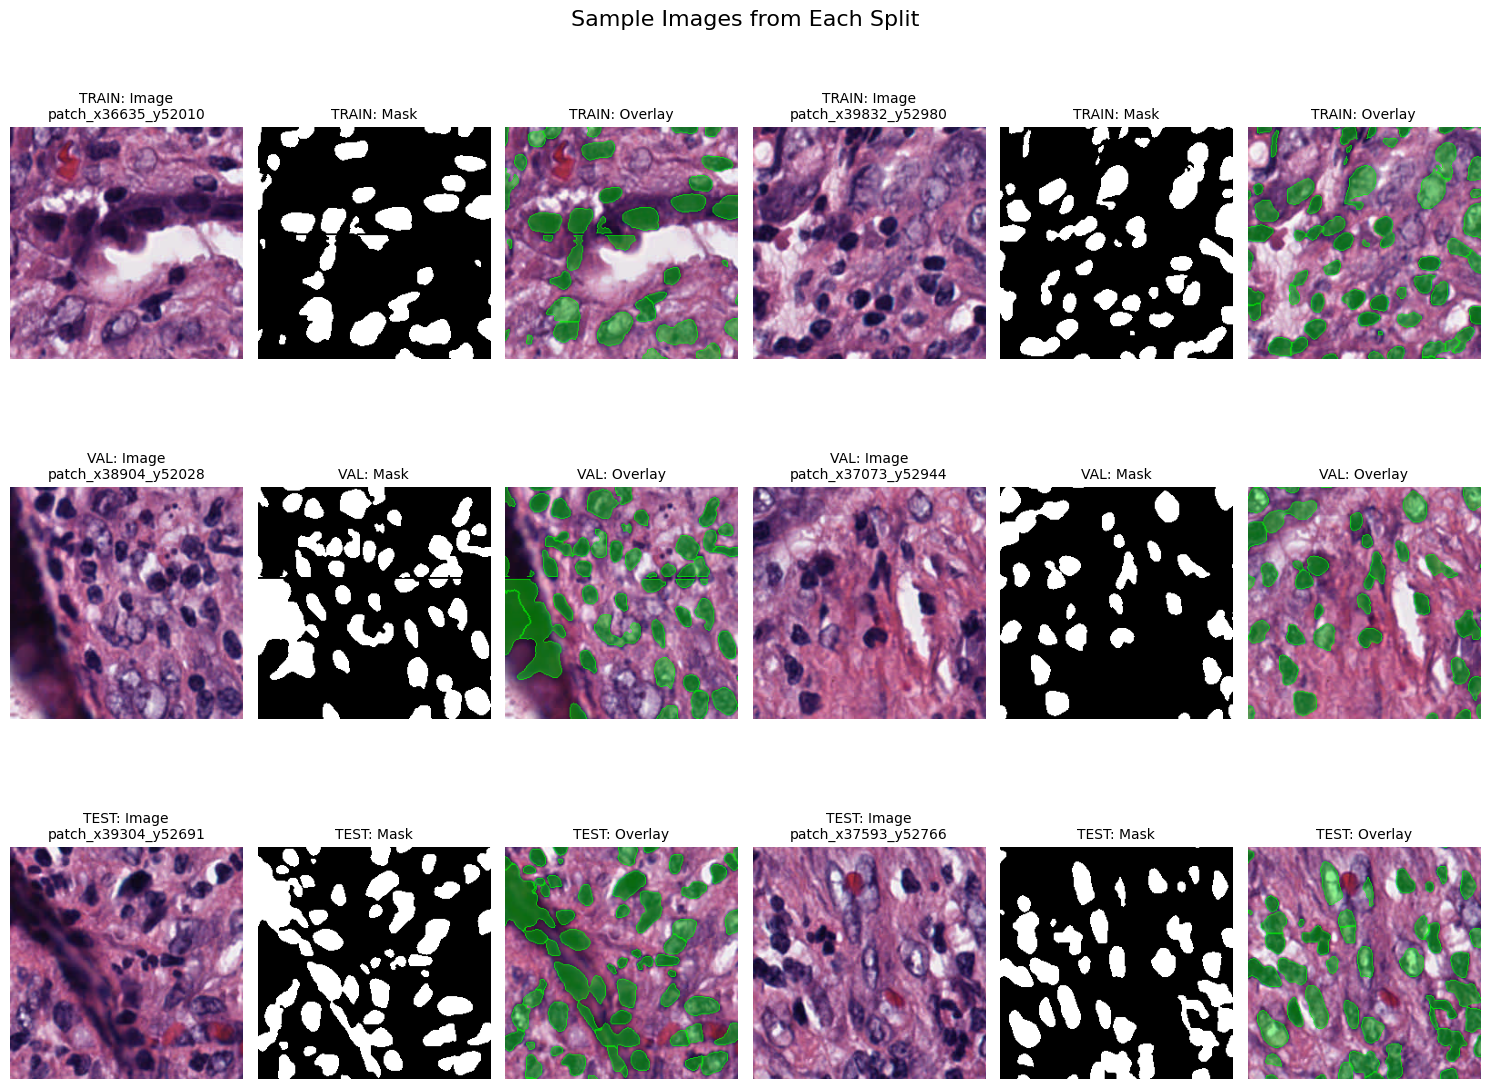


Data splitting completed successfully!


In [4]:
import os
import shutil
import random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import cv2

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)

def create_data_splits(input_base_path, output_base_path="/kaggle/working", train_ratio=0.7, val_ratio=0.15, test_ratio=0.15):
    """
    Split the lung dataset into train, validation, and test sets.
    
    Args:
        input_base_path (str): Path to the input data (e.g., /kaggle/input/data-lung/kaggle/working)
        output_base_path (str): Path where splits will be saved (e.g., /kaggle/working)
        train_ratio (float): Proportion of data for training
        val_ratio (float): Proportion of data for validation  
        test_ratio (float): Proportion of data for testing
    """
    
    # Define input paths
    training_data_path = Path(input_base_path) / "training_data"
    images_path = training_data_path / "images"
    masks_path = training_data_path / "masks"
    overlays_path = training_data_path / "overlays"
    
    # Get all image filenames (assuming they're the reference for splits)
    image_files = list(images_path.glob("*"))
    image_names = [f.stem for f in image_files]  # Get filenames without extension
    
    # Shuffle the data
    random.shuffle(image_names)
    
    # Calculate split indices
    total_samples = len(image_names)
    train_end = int(total_samples * train_ratio)
    val_end = train_end + int(total_samples * val_ratio)
    
    # Split the data
    train_names = image_names[:train_end]
    val_names = image_names[train_end:val_end]
    test_names = image_names[val_end:]
    
    print(f"Total samples: {total_samples}")
    print(f"Train: {len(train_names)} samples ({len(train_names)/total_samples*100:.1f}%)")
    print(f"Validation: {len(val_names)} samples ({len(val_names)/total_samples*100:.1f}%)")
    print(f"Test: {len(test_names)} samples ({len(test_names)/total_samples*100:.1f}%)")
    
    # Create split directories
    splits = ['train', 'val', 'test']
    split_data = {'train': train_names, 'val': val_names, 'test': test_names}
    
    for split in splits:
        # Create directories for each split in output location
        split_path = Path(output_base_path) / split
        split_path.mkdir(exist_ok=True)
        
        (split_path / "images").mkdir(exist_ok=True)
        (split_path / "masks").mkdir(exist_ok=True)
        (split_path / "overlays").mkdir(exist_ok=True)
        
        # Copy files to respective split directories
        for name in split_data[split]:
            # Find files with this name (handling different extensions)
            for img_file in images_path.glob(f"{name}.*"):
                shutil.copy2(img_file, split_path / "images")
                
            for mask_file in masks_path.glob(f"{name}.*"):
                shutil.copy2(mask_file, split_path / "masks")
                
            for overlay_file in overlays_path.glob(f"{name}.*"):
                shutil.copy2(overlay_file, split_path / "overlays")
    
    return train_names, val_names, test_names

def visualize_samples(output_base_path, num_samples=3):
    """
    Visualize sample images from each split (train, val, test).
    
    Args:
        output_base_path (str): Path to the output directory where splits are saved
        num_samples (int): Number of samples to visualize from each split
    """
    
    splits = ['train', 'val', 'test']
    
    fig, axes = plt.subplots(len(splits), num_samples * 3, figsize=(15, 12))
    fig.suptitle('Sample Images from Each Split', fontsize=16, y=0.98)
    
    for split_idx, split in enumerate(splits):
        split_path = Path(output_base_path) / split
        images_path = split_path / "images"
        masks_path = split_path / "masks"
        overlays_path = split_path / "overlays"
        
        # Get random samples from this split
        image_files = list(images_path.glob("*"))
        sample_files = random.sample(image_files, min(num_samples, len(image_files)))
        
        for sample_idx, img_file in enumerate(sample_files):
            name = img_file.stem
            
            # Load image, mask, and overlay
            image = Image.open(img_file)
            
            # Find corresponding mask and overlay files
            mask_file = list(masks_path.glob(f"{name}.*"))[0] if list(masks_path.glob(f"{name}.*")) else None
            overlay_file = list(overlays_path.glob(f"{name}.*"))[0] if list(overlays_path.glob(f"{name}.*")) else None
            
            # Plot image
            col_idx = sample_idx * 3
            axes[split_idx, col_idx].imshow(image, cmap='gray')
            axes[split_idx, col_idx].set_title(f'{split.upper()}: Image\n{name}', fontsize=10)
            axes[split_idx, col_idx].axis('off')
            
            # Plot mask
            if mask_file:
                mask = Image.open(mask_file)
                axes[split_idx, col_idx + 1].imshow(mask, cmap='gray')
                axes[split_idx, col_idx + 1].set_title(f'{split.upper()}: Mask', fontsize=10)
                axes[split_idx, col_idx + 1].axis('off')
            else:
                axes[split_idx, col_idx + 1].text(0.5, 0.5, 'No Mask', ha='center', va='center')
                axes[split_idx, col_idx + 1].set_title(f'{split.upper()}: Mask', fontsize=10)
                axes[split_idx, col_idx + 1].axis('off')
            
            # Plot overlay
            if overlay_file:
                overlay = Image.open(overlay_file)
                axes[split_idx, col_idx + 2].imshow(overlay)
                axes[split_idx, col_idx + 2].set_title(f'{split.upper()}: Overlay', fontsize=10)
                axes[split_idx, col_idx + 2].axis('off')
            else:
                axes[split_idx, col_idx + 2].text(0.5, 0.5, 'No Overlay', ha='center', va='center')
                axes[split_idx, col_idx + 2].set_title(f'{split.upper()}: Overlay', fontsize=10)
                axes[split_idx, col_idx + 2].axis('off')
    
    plt.tight_layout()
    plt.show()

def get_split_statistics(output_base_path):
    """
    Get statistics about the data splits.
    
    Args:
        output_base_path (str): Path to the output directory where splits are saved
    """
    splits = ['train', 'val', 'test']
    
    print("\n" + "="*50)
    print("DATA SPLIT STATISTICS")
    print("="*50)
    
    for split in splits:
        split_path = Path(output_base_path) / split
        if split_path.exists():
            images_count = len(list((split_path / "images").glob("*")))
            masks_count = len(list((split_path / "masks").glob("*")))
            overlays_count = len(list((split_path / "overlays").glob("*")))
            
            print(f"\n{split.upper()} SET:")
            print(f"  Images: {images_count}")
            print(f"  Masks: {masks_count}")
            print(f"  Overlays: {overlays_count}")
        else:
            print(f"\n{split.upper()} SET: Not found")

# Usage example:
if __name__ == "__main__":
    # Set your paths here
    INPUT_PATH = "/kaggle/input/data-lung/kaggle/working"  # Input path (read-only)
    OUTPUT_PATH = "/kaggle/working"  # Output path (writable)
    
    # Create the data splits
    print("Creating data splits...")
    train_names, val_names, test_names = create_data_splits(INPUT_PATH, OUTPUT_PATH)
    
    # Get statistics
    get_split_statistics(OUTPUT_PATH)
    
    # Visualize samples from each split
    print("\nCreating visualizations...")
    visualize_samples(OUTPUT_PATH, num_samples=2)
    
    print("\nData splitting completed successfully!")

In [5]:
import os
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

def load_image_paths(base_path, split):
    """
    Load all image and mask paths for a given split.
    
    Args:
        base_path (str): Path to the data directory
        split (str): 'train', 'val', or 'test'
    
    Returns:
        tuple: (image_paths, mask_paths)
    """
    split_path = Path(base_path) / split
    images_path = split_path / "images"
    masks_path = split_path / "masks"
    
    # Get all image files
    image_files = sorted(list(images_path.glob("*")))
    image_paths = [str(f) for f in image_files]
    
    # Get corresponding mask files
    mask_paths = []
    for img_file in image_files:
        name = img_file.stem
        # Find corresponding mask file
        mask_file = list(masks_path.glob(f"{name}.*"))
        if mask_file:
            mask_paths.append(str(mask_file[0]))
        else:
            mask_paths.append(None)  # Handle missing masks
    
    print(f"{split.upper()} set: {len(image_paths)} images, {len([m for m in mask_paths if m is not None])} masks")
    
    return image_paths, mask_paths

def load_and_preprocess_image(image_path, target_size=(256, 256)):
    """
    Load and preprocess a single image.
    
    Args:
        image_path (str): Path to the image
        target_size (tuple): Target size (height, width)
    
    Returns:
        numpy.ndarray: Preprocessed image
    """
    # Load image
    image = cv2.imread(image_path)
    if image is None:
        # Try with PIL if cv2 fails
        image = np.array(Image.open(image_path))
        if len(image.shape) == 3 and image.shape[2] == 3:
            image = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    
    # Convert to RGB if it's BGR
    if len(image.shape) == 3:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    # Resize image
    image = cv2.resize(image, target_size)
    
    # Convert to float32 and normalize to [0, 1]
    image = image.astype(np.float32) / 255.0
    
    return image

def load_and_preprocess_mask(mask_path, target_size=(256, 256)):
    """
    Load and preprocess a single mask.
    
    Args:
        mask_path (str): Path to the mask
        target_size (tuple): Target size (height, width)
    
    Returns:
        numpy.ndarray: Preprocessed mask
    """
    if mask_path is None:
        # Return empty mask if no mask file
        return np.zeros(target_size, dtype=np.float32)
    
    # Load mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        # Try with PIL if cv2 fails
        mask = np.array(Image.open(mask_path).convert('L'))
    
    # Resize mask
    mask = cv2.resize(mask, target_size)
    
    # Normalize mask to [0, 1] and threshold
    mask = mask.astype(np.float32) / 255.0
    mask = (mask > 0.5).astype(np.float32)  # Binary threshold
    
    return mask

Using device: cuda


In [6]:
def create_data_generators(base_path, batch_size=16, target_size=(256, 256), augment=True):
    """
    Create data generators for train, validation, and test sets.
    
    Args:
        base_path (str): Path to the data directory
        batch_size (int): Batch size for data loaders
        target_size (tuple): Target image size (height, width)
        augment (bool): Whether to apply data augmentation
    
    Returns:
        tuple: (train_loader, val_loader, test_loader)
    """
    
    # Define augmentation transforms
    if augment:
        train_transform = A.Compose([
            A.Rotate(limit=15, p=0.5),
            A.HorizontalFlip(p=0.5),
            A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
            A.GaussianBlur(blur_limit=3, p=0.3),
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ])
    else:
        train_transform = A.Compose([
            A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
            ToTensorV2()
        ])
    
    val_test_transform = A.Compose([
        A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
        ToTensorV2()
    ])
    
    # Load paths for each split
    train_img_paths, train_mask_paths = load_image_paths(base_path, 'train')
    val_img_paths, val_mask_paths = load_image_paths(base_path, 'val')
    test_img_paths, test_mask_paths = load_image_paths(base_path, 'test')
    
    # Create datasets
    train_dataset = create_dataset(train_img_paths, train_mask_paths, train_transform, target_size)
    val_dataset = create_dataset(val_img_paths, val_mask_paths, val_test_transform, target_size)
    test_dataset = create_dataset(test_img_paths, test_mask_paths, val_test_transform, target_size)
    
    # Create data loaders
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
    
    return train_loader, val_loader, test_loader

def create_dataset(image_paths, mask_paths, transform, target_size):
    """
    Create a dataset from image and mask paths.
    
    Args:
        image_paths (list): List of image paths
        mask_paths (list): List of mask paths
        transform: Albumentations transform
        target_size (tuple): Target size (height, width)
    
    Returns:
        LungSegmentationDataset: Dataset object
    """
    return LungSegmentationDataset(image_paths, mask_paths, transform, target_size)

class LungSegmentationDataset(Dataset):
    """Dataset for lung segmentation."""
    
    def __init__(self, image_paths, mask_paths, transform=None, target_size=(256, 256)):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform
        self.target_size = target_size
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        # Load image
        image = load_and_preprocess_image(self.image_paths[idx], self.target_size)
        
        # Load mask
        mask = load_and_preprocess_mask(self.mask_paths[idx], self.target_size)
        
        # Apply transforms
        if self.transform:
            # Convert to uint8 for albumentations
            image_uint8 = (image * 255).astype(np.uint8)
            mask_uint8 = (mask * 255).astype(np.uint8)
            
            augmented = self.transform(image=image_uint8, mask=mask_uint8)
            image = augmented['image']
            mask = augmented['mask']
            
            # Convert mask back to float and ensure it's binary
            if isinstance(mask, torch.Tensor):
                mask = mask.float() / 255.0
                mask = (mask > 0.5).float()
            else:
                mask = mask.astype(np.float32) / 255.0
                mask = (mask > 0.5).astype(np.float32)
                mask = torch.from_numpy(mask)
        else:
            # Convert to tensors
            image = torch.from_numpy(image.transpose(2, 0, 1))  # HWC to CHW
            mask = torch.from_numpy(mask).unsqueeze(0)  # Add channel dimension
        
        return image, mask

def visualize_batch(data_loader, num_samples=4, denormalize=True):
    """
    Visualize a batch of images and masks.
    
    Args:
        data_loader: DataLoader object
        num_samples (int): Number of samples to visualize
        denormalize (bool): Whether to denormalize images
    """
    # Get a batch
    images, masks = next(iter(data_loader))
    
    # Denormalize if needed
    if denormalize:
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        images = images * std + mean
        images = torch.clamp(images, 0, 1)
    
    # Plot
    fig, axes = plt.subplots(2, num_samples, figsize=(15, 8))
    fig.suptitle('Sample Images and Masks from Data Loader', fontsize=16)
    
    for i in range(min(num_samples, len(images))):
        # Plot image
        img = images[i].permute(1, 2, 0).numpy()  # CHW to HWC
        axes[0, i].imshow(img)
        axes[0, i].set_title(f'Image {i+1}')
        axes[0, i].axis('off')
        
        # Plot mask
        mask = masks[i].squeeze().numpy()  # Remove channel dimension
        axes[1, i].imshow(mask, cmap='gray')
        axes[1, i].set_title(f'Mask {i+1}')
        axes[1, i].axis('off')
    
    plt.tight_layout()
    plt.show()

def get_data_statistics(data_loader):
    """
    Get statistics about the dataset.
    
    Args:
        data_loader: DataLoader object
    
    Returns:
        dict: Statistics dictionary
    """
    total_samples = 0
    total_pixels = 0
    positive_pixels = 0
    
    print("Calculating dataset statistics...")
    for images, masks in data_loader:
        batch_size = images.shape[0]
        total_samples += batch_size
        
        # Count pixels
        batch_pixels = masks.numel()
        batch_positive = masks.sum().item()
        
        total_pixels += batch_pixels
        positive_pixels += batch_positive
    
    stats = {
        'total_samples': total_samples,
        'total_pixels': total_pixels,
        'positive_pixels': positive_pixels,
        'negative_pixels': total_pixels - positive_pixels,
        'positive_ratio': positive_pixels / total_pixels,
        'negative_ratio': (total_pixels - positive_pixels) / total_pixels
    }
    
    return stats


In [8]:
BASE_PATH = "/kaggle/working/"  # Update this to your actual path
    
    # Configuration
BATCH_SIZE = 16
TARGET_SIZE = (256, 256)

print("Loading data...")

# Create data loaders
train_loader, val_loader, test_loader = create_data_generators(
    BASE_PATH, 
    batch_size=BATCH_SIZE,
    target_size=TARGET_SIZE,
    augment=True
)

Loading data...
TRAIN set: 1404 images, 1404 masks
VAL set: 301 images, 301 masks
TEST set: 302 images, 302 masks


In [9]:
train_stats = get_data_statistics(train_loader)
val_stats = get_data_statistics(val_loader)
test_stats = get_data_statistics(test_loader)

Calculating dataset statistics...
Calculating dataset statistics...
Calculating dataset statistics...


In [10]:
print(f"\nTrain set statistics:")
print(f"  Samples: {train_stats['total_samples']}")
print(f"  Positive ratio: {train_stats['positive_ratio']:.4f}")
print(f"  Negative ratio: {train_stats['negative_ratio']:.4f}")


Train set statistics:
  Samples: 1404
  Positive ratio: 0.2359
  Negative ratio: 0.7641


In [11]:
print(f"\nValidation set statistics:")
print(f"  Samples: {val_stats['total_samples']}")
print(f"  Positive ratio: {val_stats['positive_ratio']:.4f}")
print(f"  Negative ratio: {val_stats['negative_ratio']:.4f}")

print(f"\nTest set statistics:")
print(f"  Samples: {test_stats['total_samples']}")
print(f"  Positive ratio: {test_stats['positive_ratio']:.4f}")
print(f"  Negative ratio: {test_stats['negative_ratio']:.4f}")

  Samples: 301
  Positive ratio: 0.2366
  Negative ratio: 0.7634

Test set statistics:
  Samples: 302
  Positive ratio: 0.2431
  Negative ratio: 0.7569


In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F

def conv_block(in_channels, out_channels):
    """
    Create a convolutional block with two conv layers, batch norm, and ReLU.
    """
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )

def down_block(in_channels, out_channels):
    """
    Create a downsampling block with max pooling and conv block.
    """
    return nn.Sequential(
        nn.MaxPool2d(kernel_size=2, stride=2),
        conv_block(in_channels, out_channels)
    )


In [14]:
def up_block(in_channels, out_channels):
    """
    Create an upsampling block with transpose convolution.
    """
    return nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)

def create_unet_model(in_channels=3, out_channels=1, features=[64, 128, 256, 512]):
    """
    Create a U-Net model.
    
    Args:
        in_channels (int): Number of input channels
        out_channels (int): Number of output channels
        features (list): List of feature dimensions for each level
    
    Returns:
        nn.Module: U-Net model
    """
    
    class UNet(nn.Module):
        def __init__(self, in_channels, out_channels, features):
            super(UNet, self).__init__()
            
            # Encoder (downsampling path)
            self.encoder1 = conv_block(in_channels, features[0])
            self.encoder2 = down_block(features[0], features[1])
            self.encoder3 = down_block(features[1], features[2])
            self.encoder4 = down_block(features[2], features[3])
            
            # Bottleneck
            self.bottleneck = down_block(features[3], features[3] * 2)
            
            # Decoder (upsampling path)
            self.upconv4 = up_block(features[3] * 2, features[3])
            self.decoder4 = conv_block(features[3] * 2, features[3])
            
            self.upconv3 = up_block(features[3], features[2])
            self.decoder3 = conv_block(features[2] * 2, features[2])
            
            self.upconv2 = up_block(features[2], features[1])
            self.decoder2 = conv_block(features[1] * 2, features[1])
            
            self.upconv1 = up_block(features[1], features[0])
            self.decoder1 = conv_block(features[0] * 2, features[0])
            
            # Final classifier
            self.final_conv = nn.Conv2d(features[0], out_channels, kernel_size=1)
            
        def forward(self, x):
            # Encoder
            enc1 = self.encoder1(x)
            enc2 = self.encoder2(enc1)
            enc3 = self.encoder3(enc2)
            enc4 = self.encoder4(enc3)
            
            # Bottleneck
            bottleneck = self.bottleneck(enc4)
            
            # Decoder with skip connections
            dec4 = self.upconv4(bottleneck)
            dec4 = torch.cat([dec4, enc4], dim=1)
            dec4 = self.decoder4(dec4)
            
            dec3 = self.upconv3(dec4)
            dec3 = torch.cat([dec3, enc3], dim=1)
            dec3 = self.decoder3(dec3)
            
            dec2 = self.upconv2(dec3)
            dec2 = torch.cat([dec2, enc2], dim=1)
            dec2 = self.decoder2(dec2)
            
            dec1 = self.upconv1(dec2)
            dec1 = torch.cat([dec1, enc1], dim=1)
            dec1 = self.decoder1(dec1)
            
            # Final output
            output = self.final_conv(dec1)
            return torch.sigmoid(output)
    
    return UNet(in_channels, out_channels, features)

# Create the model
model = create_unet_model(in_channels=3, out_channels=1, features=[64, 128, 256, 512])

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def dice_coefficient(pred, target, smooth=1e-7):
    """
    Calculate Dice coefficient.
    
    Args:
        pred (torch.Tensor): Predicted masks (0-1)
        target (torch.Tensor): Ground truth masks (0-1)
        smooth (float): Smoothing factor to avoid division by zero
    
    Returns:
        torch.Tensor: Dice coefficient
    """
    pred = pred.view(-1)
    target = target.view(-1)
    
    intersection = (pred * target).sum()
    dice = (2. * intersection + smooth) / (pred.sum() + target.sum() + smooth)
    
    return dice

def iou_coefficient(pred, target, smooth=1e-7):
    """
    Calculate IoU (Intersection over Union) coefficient.
    
    Args:
        pred (torch.Tensor): Predicted masks (0-1)
        target (torch.Tensor): Ground truth masks (0-1)
        smooth (float): Smoothing factor to avoid division by zero
    
    Returns:
        torch.Tensor: IoU coefficient
    """
    pred = pred.view(-1)
    target = target.view(-1)
    
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    iou = (intersection + smooth) / (union + smooth)
    
    return iou

def pixel_accuracy(pred, target):
    """
    Calculate pixel-wise accuracy.
    
    Args:
        pred (torch.Tensor): Predicted masks (0-1)
        target (torch.Tensor): Ground truth masks (0-1)
    
    Returns:
        torch.Tensor: Pixel accuracy
    """
    pred_binary = (pred > 0.5).float()
    correct = (pred_binary == target).float()
    accuracy = correct.sum() / correct.numel()
    
    return accuracy

def sensitivity_specificity(pred, target):
    """
    Calculate sensitivity (recall) and specificity.
    
    Args:
        pred (torch.Tensor): Predicted masks (0-1)
        target (torch.Tensor): Ground truth masks (0-1)
    
    Returns:
        tuple: (sensitivity, specificity)
    """
    pred_binary = (pred > 0.5).float()
    
    # True positives, false positives, true negatives, false negatives
    tp = ((pred_binary == 1) & (target == 1)).float().sum()
    fp = ((pred_binary == 1) & (target == 0)).float().sum()
    tn = ((pred_binary == 0) & (target == 0)).float().sum()
    fn = ((pred_binary == 0) & (target == 1)).float().sum()
    
    # Sensitivity (True Positive Rate)
    sensitivity = tp / (tp + fn + 1e-7)
    
    # Specificity (True Negative Rate)
    specificity = tn / (tn + fp + 1e-7)
    
    return sensitivity, specificity

class DiceLoss(nn.Module):
    """Dice Loss for segmentation."""
    
    def __init__(self, smooth=1e-7):
        super(DiceLoss, self).__init__()
        self.smooth = smooth
    
    def forward(self, pred, target):
        return 1 - dice_coefficient(pred, target, self.smooth)

class IoULoss(nn.Module):
    """IoU Loss for segmentation."""
    
    def __init__(self, smooth=1e-7):
        super(IoULoss, self).__init__()
        self.smooth = smooth
    
    def forward(self, pred, target):
        return 1 - iou_coefficient(pred, target, self.smooth)

class CombinedLoss(nn.Module):
    """Combined BCE + Dice Loss."""
    
    def __init__(self, bce_weight=0.5, dice_weight=0.5):
        super(CombinedLoss, self).__init__()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.bce_loss = nn.BCELoss()
        self.dice_loss = DiceLoss()
    
    def forward(self, pred, target):
        bce = self.bce_loss(pred, target)
        dice = self.dice_loss(pred, target)
        return self.bce_weight * bce + self.dice_weight * dice

class FocalLoss(nn.Module):
    """Focal Loss for handling class imbalance."""
    
    def __init__(self, alpha=1, gamma=2, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
    
    def forward(self, pred, target):
        bce_loss = F.binary_cross_entropy(pred, target, reduction='none')
        pt = torch.exp(-bce_loss)
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

def calculate_all_metrics(pred, target):
    """
    Calculate all metrics at once.
    
    Args:
        pred (torch.Tensor): Predicted masks
        target (torch.Tensor): Ground truth masks
    
    Returns:
        dict: Dictionary containing all metrics
    """
    with torch.no_grad():
        # Convert to CPU for sklearn metrics
        pred_np = (pred > 0.5).cpu().numpy().flatten()
        target_np = target.cpu().numpy().flatten()
        
        dice = dice_coefficient(pred, target)
        iou = iou_coefficient(pred, target)
        pixel_acc = pixel_accuracy(pred, target)
        sensitivity, specificity = sensitivity_specificity(pred, target)
        
        # Calculate sklearn metrics
        accuracy = accuracy_score(target_np, pred_np)
        precision = precision_score(target_np, pred_np, zero_division=0)
        recall = recall_score(target_np, pred_np, zero_division=0)
        f1 = f1_score(target_np, pred_np, zero_division=0)
        
        metrics = {
            'dice': dice.item(),
            'iou': iou.item(),
            'pixel_accuracy': pixel_acc.item(),
            'sensitivity': sensitivity.item(),
            'specificity': specificity.item(),
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1
        }
        
        return metrics

# Initialize loss functions
criterion_bce = nn.BCELoss()
criterion_dice = DiceLoss()
criterion_iou = IoULoss()
criterion_combined = CombinedLoss(bce_weight=0.5, dice_weight=0.5)
criterion_focal = FocalLoss(alpha=1, gamma=2)

# Choose your loss function
criterion = criterion_combined  # You can change this to any loss function above

print("Loss functions and metrics initialized!")
print(f"Using loss function: {type(criterion).__name__}")




Loss functions and metrics initialized!
Using loss function: CombinedLoss


In [18]:
# Fix the dimension mismatch between model output and masks
import torch

# Check current dimensions
print("Current dimensions:")
print(f"Model output shape: {test_output.shape}")  # [16, 1, 256, 256]
print(f"Mask shape: {test_masks.shape}")           # [16, 256, 256]

# Fix: Add channel dimension to masks to match model output
test_masks_fixed = test_masks.unsqueeze(1)  # Add channel dimension
print(f"Fixed mask shape: {test_masks_fixed.shape}")  # [16, 1, 256, 256]

# Test loss calculation with fixed dimensions
test_loss = criterion(test_output, test_masks_fixed)
print(f"Test loss: {test_loss.item():.4f}")

# Test metrics with fixed dimensions
test_dice = dice_coefficient(test_output, test_masks_fixed)
test_iou = iou_coefficient(test_output, test_masks_fixed)
print(f"Test Dice: {test_dice.item():.4f}")
print(f"Test IoU: {test_iou.item():.4f}")

# Update the training functions to handle dimension mismatch
def train_one_epoch_fixed(model, train_loader, criterion, optimizer, device):
    """Train for one epoch with dimension fix."""
    model.train()
    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    
    train_bar = tqdm(train_loader, desc='Training')
    
    for batch_idx, (images, masks) in enumerate(train_bar):
        images = images.to(device)
        masks = masks.to(device)
        
        # Fix dimension mismatch
        if len(masks.shape) == 3:  # [B, H, W]
            masks = masks.unsqueeze(1)  # [B, 1, H, W]
        
        # Zero gradients
        optimizer.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, masks)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        # Calculate metrics
        with torch.no_grad():
            dice = dice_coefficient(outputs, masks)
            iou = iou_coefficient(outputs, masks)
        
        # Update running metrics
        running_loss += loss.item()
        running_dice += dice.item()
        running_iou += iou.item()
        
        # Update progress bar
        train_bar.set_postfix({
            'Loss': f'{loss.item():.4f}',
            'Dice': f'{dice.item():.4f}',
            'IoU': f'{iou.item():.4f}'
        })
    
    epoch_loss = running_loss / len(train_loader)
    epoch_dice = running_dice / len(train_loader)
    epoch_iou = running_iou / len(train_loader)
    
    return epoch_loss, epoch_dice, epoch_iou

def validate_one_epoch_fixed(model, val_loader, criterion, device):
    """Validate for one epoch with dimension fix."""
    model.eval()
    running_loss = 0.0
    all_metrics = {
        'dice': [],
        'iou': [],
        'pixel_accuracy': [],
        'sensitivity': [],
        'specificity': [],
        'accuracy': [],
        'precision': [],
        'recall': [],
        'f1_score': []
    }
    
    val_bar = tqdm(val_loader, desc='Validation')
    
    with torch.no_grad():
        for batch_idx, (images, masks) in enumerate(val_bar):
            images = images.to(device)
            masks = masks.to(device)
            
            # Fix dimension mismatch
            if len(masks.shape) == 3:  # [B, H, W]
                masks = masks.unsqueeze(1)  # [B, 1, H, W]
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, masks)
            
            running_loss += loss.item()
            
            # Calculate all metrics for this batch
            batch_metrics = calculate_all_metrics(outputs, masks)
            
            # Accumulate metrics
            for metric_name, value in batch_metrics.items():
                all_metrics[metric_name].append(value)
            
            # Update progress bar
            val_bar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Dice': f'{batch_metrics["dice"]:.4f}',
                'IoU': f'{batch_metrics["iou"]:.4f}'
            })
    
    # Calculate average metrics
    epoch_loss = running_loss / len(val_loader)
    avg_metrics = {metric: np.mean(values) for metric, values in all_metrics.items()}
    
    return epoch_loss, avg_metrics

# Test the fixed functions
print("\nTesting fixed training function...")
# Create a small test batch
test_images_small = test_images[:2]  # Take only 2 samples for quick test
test_masks_small = test_masks[:2]

# Test the fixed validation function
model.eval()
with torch.no_grad():
    outputs = model(test_images_small.to(device))
    masks_fixed = test_masks_small.to(device)
    if len(masks_fixed.shape) == 3:
        masks_fixed = masks_fixed.unsqueeze(1)
    
    loss = criterion(outputs, masks_fixed)
    metrics = calculate_all_metrics(outputs, masks_fixed)
    
    print(f"Test successful!")
    print(f"Output shape: {outputs.shape}")
    print(f"Mask shape: {masks_fixed.shape}")
    print(f"Loss: {loss.item():.4f}")
    print(f"Dice: {metrics['dice']:.4f}")

print("\nDimension fix completed! Ready for training with fixed functions.")

Current dimensions:
Model output shape: torch.Size([16, 1, 256, 256])
Mask shape: torch.Size([16, 256, 256])
Fixed mask shape: torch.Size([16, 1, 256, 256])
Test loss: 0.7477
Test Dice: 0.2918
Test IoU: 0.1708

Testing fixed training function...
Test successful!
Output shape: torch.Size([2, 1, 256, 256])
Mask shape: torch.Size([2, 1, 256, 256])
Loss: 0.6773
Dice: 0.3579

Dimension fix completed! Ready for training with fixed functions.


In [19]:
# Corrected training loop with dimension fixes
import time

# Reset training history
history = {
    'train_loss': [],
    'train_dice': [],
    'train_iou': [],
    'val_loss': [],
    'val_dice': [],
    'val_iou': [],
    'val_accuracy': [],
    'val_precision': [],
    'val_recall': [],
    'val_f1': [],
    'val_sensitivity': [],
    'val_specificity': [],
    'learning_rate': []
}

# Reset early stopping variables
best_val_dice = 0.0
patience_counter = 0
best_model_state = None

print("Starting corrected training...")
print(f"Device: {device}")
print(f"Epochs: {EPOCHS}")
print(f"Learning Rate: {LEARNING_RATE}")
print(f"Batch Size: {train_loader.batch_size}")
print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print("-" * 50)

# Training loop with dimension fixes
for epoch in range(EPOCHS):
    start_time = time.time()
    
    print(f"\nEpoch [{epoch+1}/{EPOCHS}]")
    
    # Training phase
    train_loss, train_dice, train_iou = train_one_epoch_fixed(
        model, train_loader, criterion, optimizer, device
    )
    
    # Validation phase
    val_loss, val_metrics = validate_one_epoch_fixed(
        model, val_loader, criterion, device
    )
    
    # Update learning rate scheduler
    scheduler.step(val_metrics['dice'])
    current_lr = optimizer.param_groups[0]['lr']
    
    # Update history
    history['train_loss'].append(train_loss)
    history['train_dice'].append(train_dice)
    history['train_iou'].append(train_iou)
    history['val_loss'].append(val_loss)
    history['val_dice'].append(val_metrics['dice'])
    history['val_iou'].append(val_metrics['iou'])
    history['val_accuracy'].append(val_metrics['accuracy'])
    history['val_precision'].append(val_metrics['precision'])
    history['val_recall'].append(val_metrics['recall'])
    history['val_f1'].append(val_metrics['f1_score'])
    history['val_sensitivity'].append(val_metrics['sensitivity'])
    history['val_specificity'].append(val_metrics['specificity'])
    history['learning_rate'].append(current_lr)
    
    # Print epoch results
    epoch_time = time.time() - start_time
    print(f"Time: {epoch_time:.2f}s")
    print(f"Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f} | Train IoU: {train_iou:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Dice: {val_metrics['dice']:.4f} | Val IoU: {val_metrics['iou']:.4f}")
    print(f"Val Acc: {val_metrics['accuracy']:.4f} | Val F1: {val_metrics['f1_score']:.4f}")
    print(f"Val Sensitivity: {val_metrics['sensitivity']:.4f} | Val Specificity: {val_metrics['specificity']:.4f}")
    print(f"Learning Rate: {current_lr:.2e}")
    
    # Save best model
    if val_metrics['dice'] > best_val_dice:
        best_val_dice = val_metrics['dice']
        patience_counter = 0
        best_model_state = model.state_dict().copy()
        save_checkpoint(model, optimizer, epoch, val_metrics['dice'], 'best_unet_model.pth')
        print(f"✓ New best model saved! Dice: {best_val_dice:.4f}")
    else:
        patience_counter += 1
        print(f"No improvement. Patience: {patience_counter}/{PATIENCE}")
    
    # Early stopping
    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping triggered after {epoch+1} epochs")
        print(f"Best validation Dice: {best_val_dice:.4f}")
        break
    
    print("-" * 50)

# Load best model
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"\nTraining completed! Best validation Dice: {best_val_dice:.4f}")
else:
    print("\nTraining completed!")

# Save final model
torch.save(model.state_dict(), 'final_unet_model.pth')
print("Final model saved as 'final_unet_model.pth'")
print("Best model saved as 'best_unet_model.pth'")

print(f"\nTraining Summary:")
print(f"Total epochs: {len(history['train_loss'])}")
print(f"Best validation Dice: {best_val_dice:.4f}")
print(f"Final train loss: {history['train_loss'][-1]:.4f}")
print(f"Final validation loss: {history['val_loss'][-1]:.4f}")

Starting corrected training...
Device: cuda
Epochs: 50
Learning Rate: 0.001
Batch Size: 16
Train batches: 88
Validation batches: 19
--------------------------------------------------

Epoch [1/50]


Validation: 100%|██████████| 19/19 [00:30<00:00,  1.61s/it, Loss=0.2392, Dice=0.7436, IoU=0.5919]


Time: 65.98s
Train Loss: 0.2982 | Train Dice: 0.6832 | Train IoU: 0.5228
Val Loss: 0.2311 | Val Dice: 0.7479 | Val IoU: 0.5977
Val Acc: 0.9200 | Val F1: 0.8394
Val Sensitivity: 0.8885 | Val Specificity: 0.9298
Learning Rate: 1.00e-03
✓ New best model saved! Dice: 0.7479
--------------------------------------------------

Epoch [2/50]


Validation: 100%|██████████| 19/19 [00:30<00:00,  1.63s/it, Loss=0.1789, Dice=0.8012, IoU=0.6684]


Time: 65.84s
Train Loss: 0.1961 | Train Dice: 0.7941 | Train IoU: 0.6589
Val Loss: 0.1795 | Val Dice: 0.7993 | Val IoU: 0.6660
Val Acc: 0.9349 | Val F1: 0.8581
Val Sensitivity: 0.8350 | Val Specificity: 0.9659
Learning Rate: 1.00e-03
✓ New best model saved! Dice: 0.7993
--------------------------------------------------

Epoch [3/50]


Validation: 100%|██████████| 19/19 [00:30<00:00,  1.59s/it, Loss=0.2730, Dice=0.7775, IoU=0.6360]


... (91 outputs left out)

Validation: 100%|██████████| 19/19 [00:30<00:00,  1.62s/it, Loss=0.0447, Dice=0.9564, IoU=0.9164]


Time: 65.73s
Train Loss: 0.0417 | Train Dice: 0.9585 | Train IoU: 0.9203
Val Loss: 0.0403 | Val Dice: 0.9593 | Val IoU: 0.9217
Val Acc: 0.9848 | Val F1: 0.9672
Val Sensitivity: 0.9518 | Val Specificity: 0.9950
Learning Rate: 5.00e-04
No improvement. Patience: 1/10
--------------------------------------------------

Epoch [50/50]


Validation: 100%|██████████| 19/19 [00:30<00:00,  1.62s/it, Loss=0.0694, Dice=0.9393, IoU=0.8855]


Time: 65.85s
Train Loss: 0.0414 | Train Dice: 0.9587 | Train IoU: 0.9208
Val Loss: 0.0618 | Val Dice: 0.9441 | Val IoU: 0.8942
Val Acc: 0.9772 | Val F1: 0.9499
Val Sensitivity: 0.9164 | Val Specificity: 0.9960
Learning Rate: 5.00e-04
No improvement. Patience: 2/10
--------------------------------------------------

Training completed! Best validation Dice: 0.9645
Final model saved as 'final_unet_model.pth'
Best model saved as 'best_unet_model.pth'

Training Summary:
Total epochs: 50
Best validation Dice: 0.9645
Final train loss: 0.0414
Final validation loss: 0.0618


Generating training visualization...
Plot saved to training_history.png


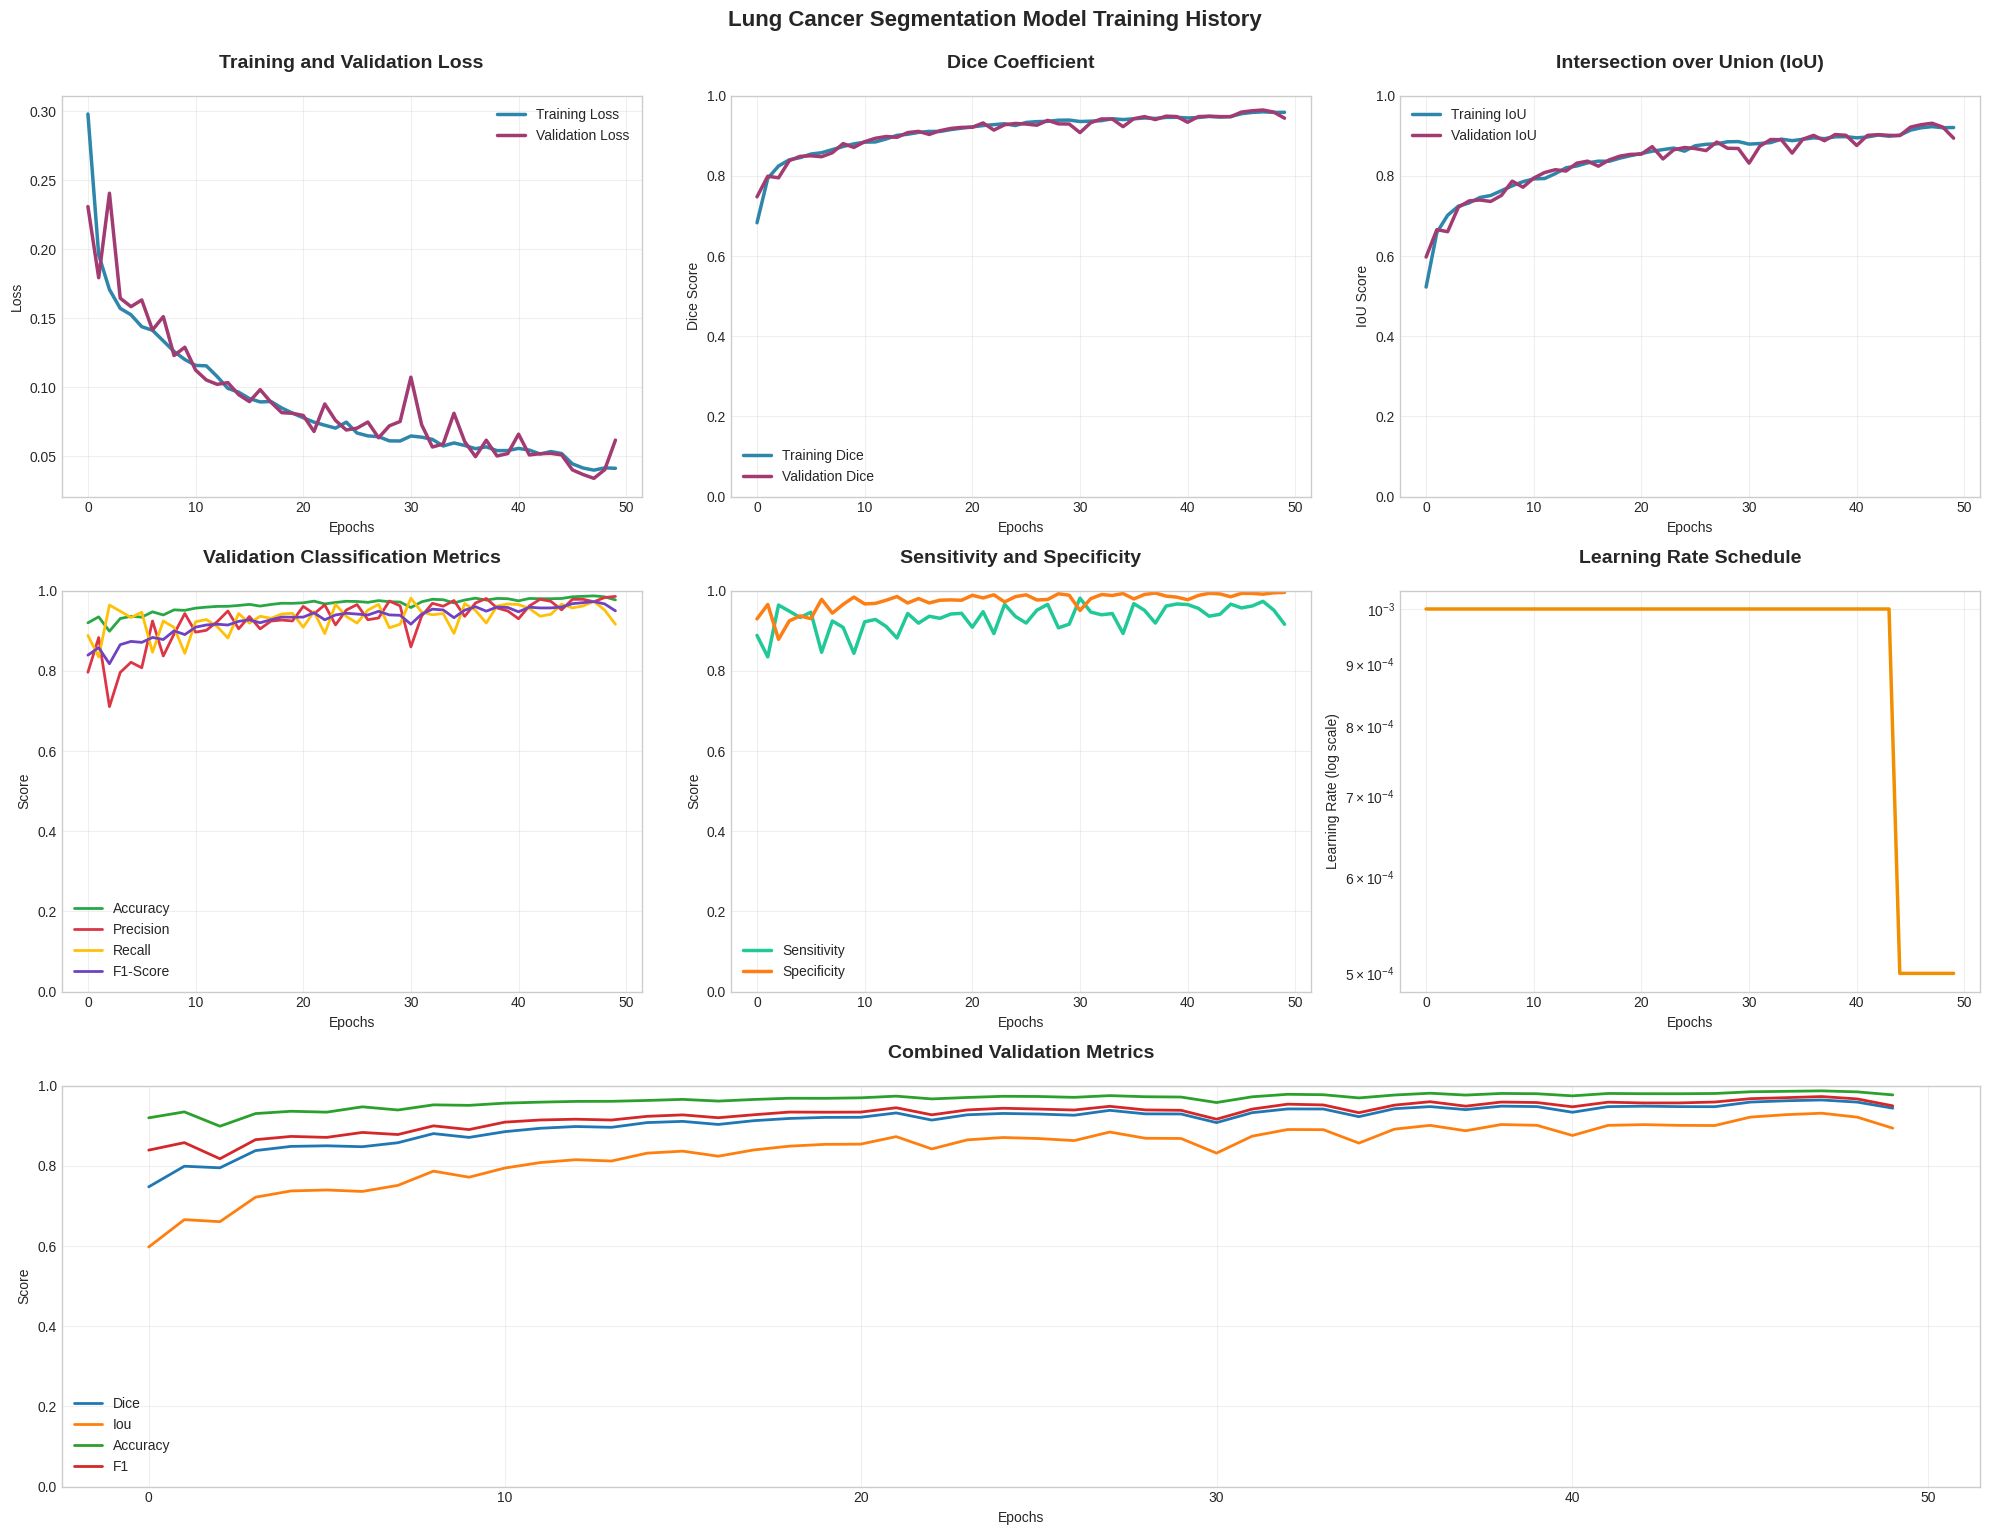

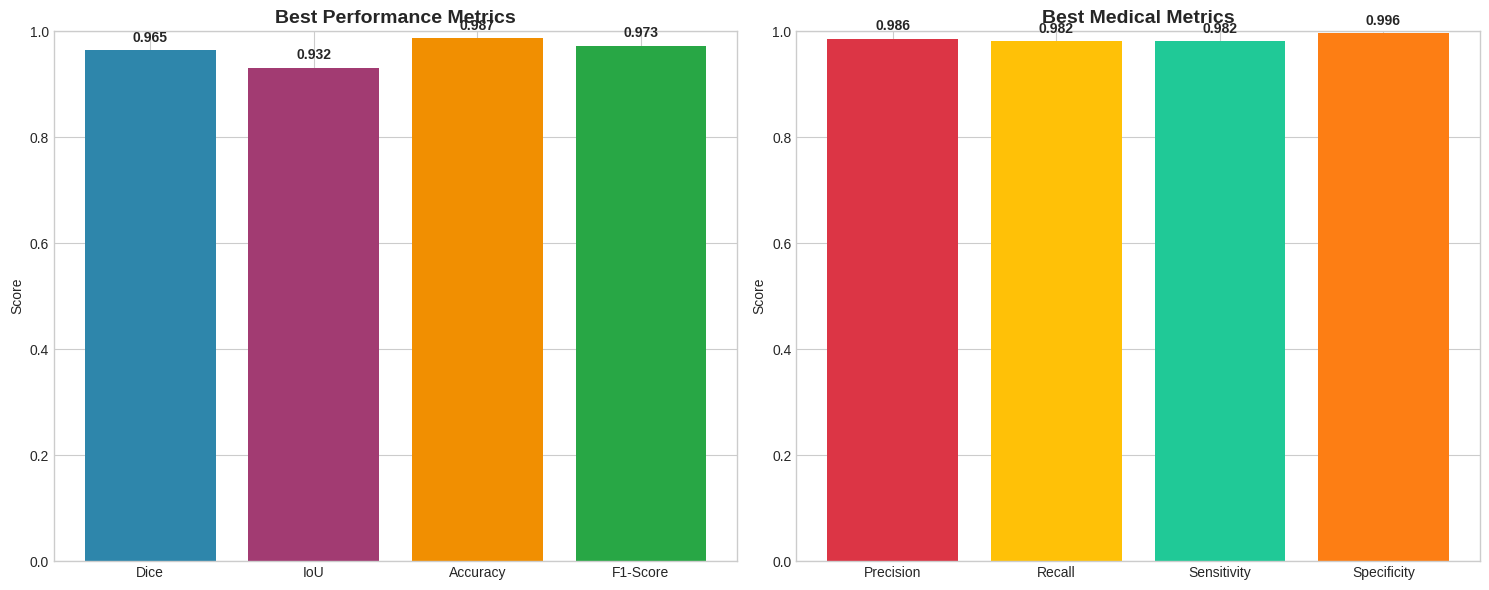

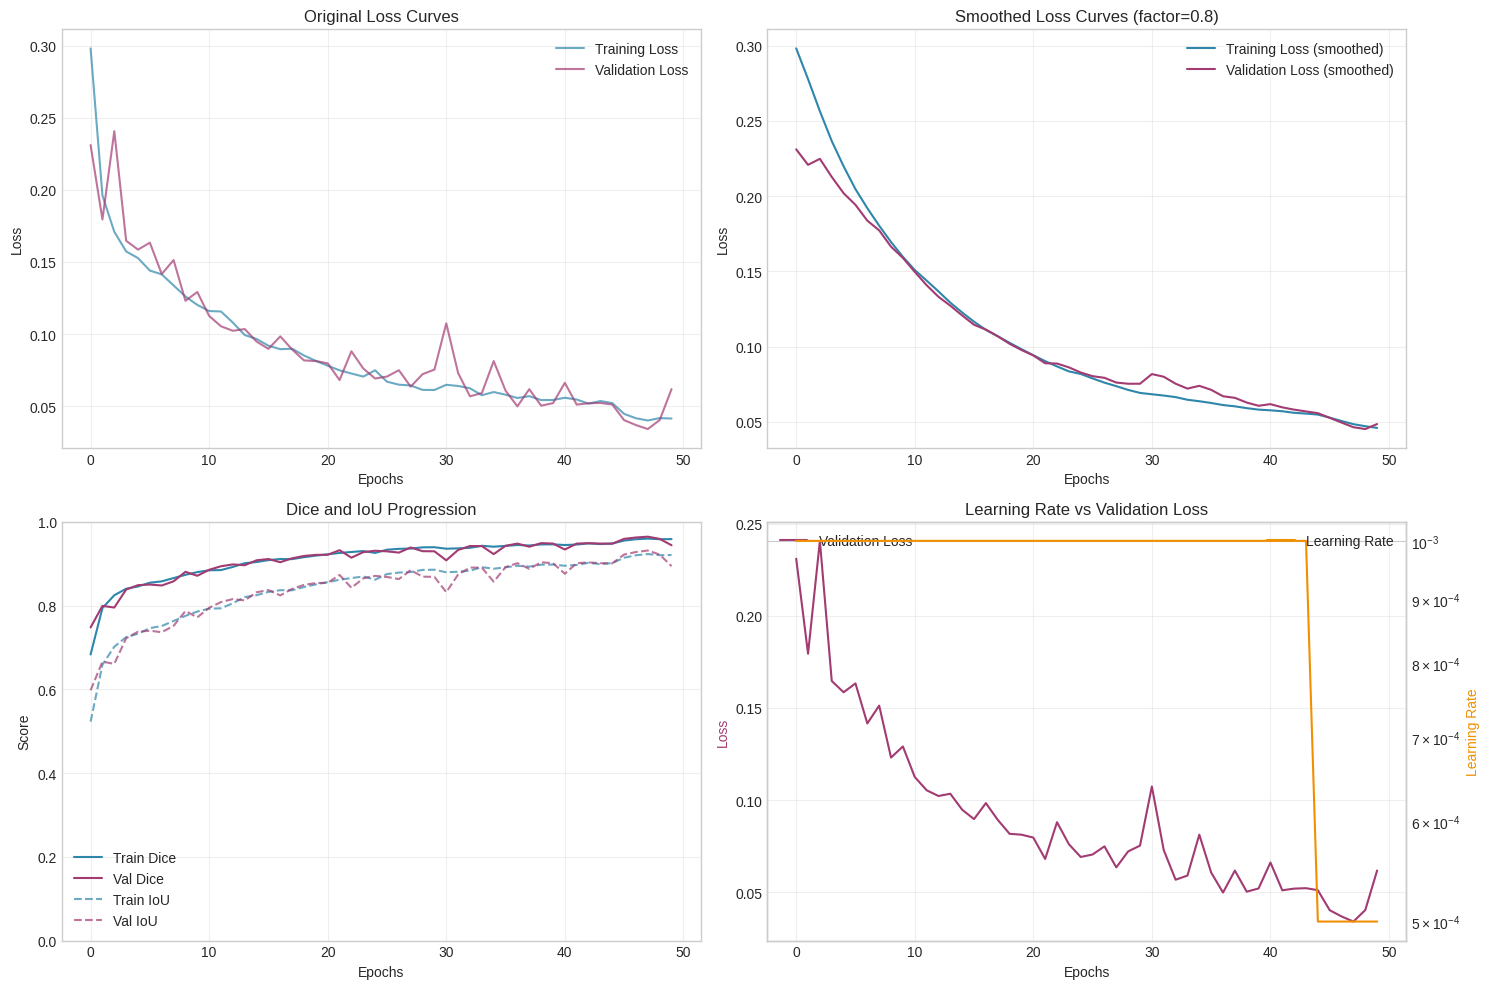

           LUNG CANCER SEGMENTATION TRAINING REPORT

📊 TRAINING SUMMARY:
   Total Epochs Trained: 50
   Best Epoch: 48
   Final Learning Rate: 5.00e-04

🎯 BEST VALIDATION METRICS:
   Dice Coefficient: 0.9645
   IoU Score:        0.9315
   Accuracy:         0.9873
   F1-Score:         0.9731

🏥 MEDICAL METRICS:
   Sensitivity:      0.9815
   Specificity:      0.9960
   Precision:        0.9860
   Recall:           0.9815

📈 LOSS PROGRESSION:
   Final Train Loss: 0.0414
   Final Val Loss:   0.0618
   Loss Reduction:   86.1%

🔍 MODEL HEALTH:
   ⚠️  Moderate overfitting (gap: 0.015)


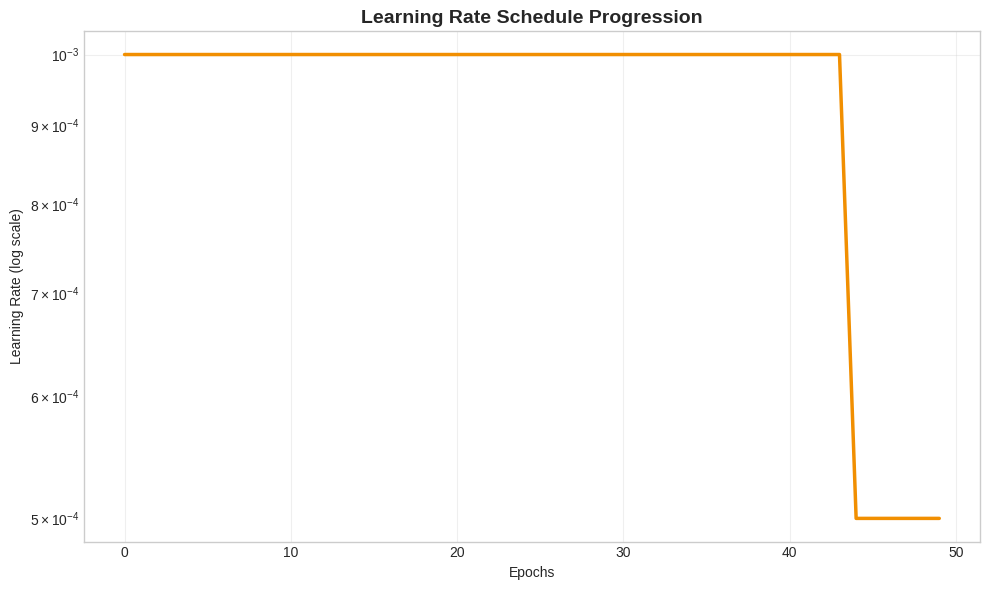

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.gridspec import GridSpec
import pandas as pd

# Set professional style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

def plot_training_history(history, save_path=None):
    """
    Comprehensive plotting of training history with medical aesthetic
    """
    # Convert history to DataFrame for easier plotting
    history_df = pd.DataFrame(history)
    
    # Create figure with subplots
    fig = plt.figure(figsize=(20, 15))
    gs = GridSpec(3, 3, figure=fig)
    
    # Colors for medical theme
    train_color = '#2E86AB'  # Professional blue
    val_color = '#A23B72'    # Professional burgundy
    accent_color = '#F18F01' # Amber accent
    
    # 1. Loss Plot
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.plot(history_df['train_loss'], label='Training Loss', color=train_color, linewidth=2.5)
    ax1.plot(history_df['val_loss'], label='Validation Loss', color=val_color, linewidth=2.5)
    ax1.set_title('Training and Validation Loss', fontsize=14, fontweight='bold', pad=20)
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Dice Coefficient Plot
    ax2 = fig.add_subplot(gs[0, 1])
    ax2.plot(history_df['train_dice'], label='Training Dice', color=train_color, linewidth=2.5)
    ax2.plot(history_df['val_dice'], label='Validation Dice', color=val_color, linewidth=2.5)
    ax2.set_title('Dice Coefficient', fontsize=14, fontweight='bold', pad=20)
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Dice Score')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 1)
    
    # 3. IoU Plot
    ax3 = fig.add_subplot(gs[0, 2])
    ax3.plot(history_df['train_iou'], label='Training IoU', color=train_color, linewidth=2.5)
    ax3.plot(history_df['val_iou'], label='Validation IoU', color=val_color, linewidth=2.5)
    ax3.set_title('Intersection over Union (IoU)', fontsize=14, fontweight='bold', pad=20)
    ax3.set_xlabel('Epochs')
    ax3.set_ylabel('IoU Score')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_ylim(0, 1)
    
    # 4. Accuracy Metrics
    ax4 = fig.add_subplot(gs[1, 0])
    ax4.plot(history_df['val_accuracy'], label='Accuracy', color='#28a745', linewidth=2)
    ax4.plot(history_df['val_precision'], label='Precision', color='#dc3545', linewidth=2)
    ax4.plot(history_df['val_recall'], label='Recall', color='#ffc107', linewidth=2)
    ax4.plot(history_df['val_f1'], label='F1-Score', color='#6f42c1', linewidth=2)
    ax4.set_title('Validation Classification Metrics', fontsize=14, fontweight='bold', pad=20)
    ax4.set_xlabel('Epochs')
    ax4.set_ylabel('Score')
    ax4.legend()
    ax4.grid(True, alpha=0.3)
    ax4.set_ylim(0, 1)
    
    # 5. Sensitivity and Specificity
    ax5 = fig.add_subplot(gs[1, 1])
    ax5.plot(history_df['val_sensitivity'], label='Sensitivity', color='#20c997', linewidth=2.5)
    ax5.plot(history_df['val_specificity'], label='Specificity', color='#fd7e14', linewidth=2.5)
    ax5.set_title('Sensitivity and Specificity', fontsize=14, fontweight='bold', pad=20)
    ax5.set_xlabel('Epochs')
    ax5.set_ylabel('Score')
    ax5.legend()
    ax5.grid(True, alpha=0.3)
    ax5.set_ylim(0, 1)
    
    # 6. Learning Rate
    ax6 = fig.add_subplot(gs[1, 2])
    ax6.semilogy(history_df['learning_rate'], color=accent_color, linewidth=2.5)
    ax6.set_title('Learning Rate Schedule', fontsize=14, fontweight='bold', pad=20)
    ax6.set_xlabel('Epochs')
    ax6.set_ylabel('Learning Rate (log scale)')
    ax6.grid(True, alpha=0.3)
    
    # 7. Combined Performance Metrics
    ax7 = fig.add_subplot(gs[2, :])
    metrics_to_plot = ['val_dice', 'val_iou', 'val_accuracy', 'val_f1']
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    
    for i, metric in enumerate(metrics_to_plot):
        ax7.plot(history_df[metric], label=metric.replace('val_', '').title(), 
                color=colors[i], linewidth=2)
    
    ax7.set_title('Combined Validation Metrics', fontsize=14, fontweight='bold', pad=20)
    ax7.set_xlabel('Epochs')
    ax7.set_ylabel('Score')
    ax7.legend()
    ax7.grid(True, alpha=0.3)
    ax7.set_ylim(0, 1)
    
    plt.tight_layout()
    plt.suptitle('Lung Cancer Segmentation Model Training History', 
                fontsize=16, fontweight='bold', y=1.02)
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        print(f"Plot saved to {save_path}")
    
    plt.show()

def plot_final_metrics_comparison(history):
    """
    Create a final comparison of best metrics achieved
    """
    # Get best values for each metric
    best_metrics = {
        'Dice': max(history['val_dice']),
        'IoU': max(history['val_iou']),
        'Accuracy': max(history['val_accuracy']),
        'F1-Score': max(history['val_f1']),
        'Precision': max(history['val_precision']),
        'Recall': max(history['val_recall']),
        'Sensitivity': max(history['val_sensitivity']),
        'Specificity': max(history['val_specificity'])
    }
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    # Bar plot for main metrics
    metrics_main = ['Dice', 'IoU', 'Accuracy', 'F1-Score']
    values_main = [best_metrics[m] for m in metrics_main]
    
    bars = ax1.bar(metrics_main, values_main, color=['#2E86AB', '#A23B72', '#F18F01', '#28a745'])
    ax1.set_title('Best Performance Metrics', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Score')
    ax1.set_ylim(0, 1)
    
    # Add value labels on bars
    for bar, value in zip(bars, values_main):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
    
    # Bar plot for medical metrics
    metrics_medical = ['Precision', 'Recall', 'Sensitivity', 'Specificity']
    values_medical = [best_metrics[m] for m in metrics_medical]
    
    bars2 = ax2.bar(metrics_medical, values_medical, color=['#dc3545', '#ffc107', '#20c997', '#fd7e14'])
    ax2.set_title('Best Medical Metrics', fontsize=14, fontweight='bold')
    ax2.set_ylabel('Score')
    ax2.set_ylim(0, 1)
    
    # Add value labels on bars
    for bar, value in zip(bars2, values_medical):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{value:.3f}', ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    return best_metrics

def plot_loss_curves_detailed(history):
    """
    Detailed view of loss curves with smoothing
    """
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))
    
    # Smoothing function
    def smooth_curve(points, factor=0.8):
        smoothed = []
        for point in points:
            if smoothed:
                previous = smoothed[-1]
                smoothed.append(previous * factor + point * (1 - factor))
            else:
                smoothed.append(point)
        return smoothed
    
    # 1. Original loss curves
    ax1.plot(history['train_loss'], alpha=0.7, label='Training Loss', color='#2E86AB')
    ax1.plot(history['val_loss'], alpha=0.7, label='Validation Loss', color='#A23B72')
    ax1.set_title('Original Loss Curves')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # 2. Smoothed loss curves
    ax2.plot(smooth_curve(history['train_loss']), label='Training Loss (smoothed)', color='#2E86AB')
    ax2.plot(smooth_curve(history['val_loss']), label='Validation Loss (smoothed)', color='#A23B72')
    ax2.set_title('Smoothed Loss Curves (factor=0.8)')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Loss')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    # 3. Dice and IoU progression
    ax3.plot(history['train_dice'], label='Train Dice', color='#2E86AB', linestyle='-')
    ax3.plot(history['val_dice'], label='Val Dice', color='#A23B72', linestyle='-')
    ax3.plot(history['train_iou'], label='Train IoU', color='#2E86AB', linestyle='--', alpha=0.7)
    ax3.plot(history['val_iou'], label='Val IoU', color='#A23B72', linestyle='--', alpha=0.7)
    ax3.set_title('Dice and IoU Progression')
    ax3.set_xlabel('Epochs')
    ax3.set_ylabel('Score')
    ax3.legend()
    ax3.grid(True, alpha=0.3)
    ax3.set_ylim(0, 1)
    
    # 4. Learning rate vs loss
    ax4_twin = ax4.twinx()
    ax4.plot(history['val_loss'], label='Validation Loss', color='#A23B72')
    ax4_twin.semilogy(history['learning_rate'], label='Learning Rate', color='#F18F01')
    ax4.set_title('Learning Rate vs Validation Loss')
    ax4.set_xlabel('Epochs')
    ax4.set_ylabel('Loss', color='#A23B72')
    ax4_twin.set_ylabel('Learning Rate', color='#F18F01')
    ax4.legend(loc='upper left')
    ax4_twin.legend(loc='upper right')
    ax4.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

def create_training_report(history):
    """
    Generate a comprehensive training report
    """
    print("="*60)
    print("           LUNG CANCER SEGMENTATION TRAINING REPORT")
    print("="*60)
    
    # Calculate best metrics
    best_dice = max(history['val_dice'])
    best_iou = max(history['val_iou'])
    best_accuracy = max(history['val_accuracy'])
    best_f1 = max(history['val_f1'])
    
    # Find epoch of best validation dice
    best_epoch = np.argmax(history['val_dice']) + 1
    
    print(f"\n📊 TRAINING SUMMARY:")
    print(f"   Total Epochs Trained: {len(history['train_loss'])}")
    print(f"   Best Epoch: {best_epoch}")
    print(f"   Final Learning Rate: {history['learning_rate'][-1]:.2e}")
    
    print(f"\n🎯 BEST VALIDATION METRICS:")
    print(f"   Dice Coefficient: {best_dice:.4f}")
    print(f"   IoU Score:        {best_iou:.4f}")
    print(f"   Accuracy:         {best_accuracy:.4f}")
    print(f"   F1-Score:         {best_f1:.4f}")
    
    print(f"\n🏥 MEDICAL METRICS:")
    print(f"   Sensitivity:      {max(history['val_sensitivity']):.4f}")
    print(f"   Specificity:      {max(history['val_specificity']):.4f}")
    print(f"   Precision:        {max(history['val_precision']):.4f}")
    print(f"   Recall:           {max(history['val_recall']):.4f}")
    
    print(f"\n📈 LOSS PROGRESSION:")
    print(f"   Final Train Loss: {history['train_loss'][-1]:.4f}")
    print(f"   Final Val Loss:   {history['val_loss'][-1]:.4f}")
    print(f"   Loss Reduction:   {((history['train_loss'][0] - history['train_loss'][-1])/history['train_loss'][0]*100):.1f}%")
    
    # Check for overfitting
    final_train_dice = history['train_dice'][-1]
    final_val_dice = history['val_dice'][-1]
    overfitting_gap = final_train_dice - final_val_dice
    
    print(f"\n🔍 MODEL HEALTH:")
    if overfitting_gap > 0.1:
        print(f"   ⚠️  Potential overfitting (gap: {overfitting_gap:.3f})")
    elif overfitting_gap < 0:
        print(f"   ✅ Model generalizing well")
    else:
        print(f"   ⚠️  Moderate overfitting (gap: {overfitting_gap:.3f})")
    
    print("="*60)

# Main execution
if __name__ == "__main__":
    # Your history dictionary should be available here
    # history = {...}  # Your training history
    
    # Generate all plots and reports
    print("Generating training visualization...")
    
    # 1. Comprehensive training history plot
    plot_training_history(history, save_path='training_history.png')
    
    # 2. Final metrics comparison
    best_metrics = plot_final_metrics_comparison(history)
    
    # 3. Detailed loss curves
    plot_loss_curves_detailed(history)
    
    # 4. Training report
    create_training_report(history)
    
    # 5. Additional: Learning rate analysis
    plt.figure(figsize=(10, 6))
    plt.semilogy(history['learning_rate'], linewidth=2.5, color='#F18F01')
    plt.title('Learning Rate Schedule Progression', fontsize=14, fontweight='bold')
    plt.xlabel('Epochs')
    plt.ylabel('Learning Rate (log scale)')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
from IPython.display import FileLink
FileLink(r'lung_data_model.zip')

/kaggle/working/lung_data_model.zip